# Preprocessing

This notebook cleans the raw data and creates the train/validation/test split. It saves one file, `hotel_bookings_clean.csv`, which every group member uses for their model, so that all models are trained and tested on exactly the same data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

hotels = pd.read_csv("hotel_bookings.csv")
print(f"Raw data: {hotels.shape[0]:,} bookings, {hotels.shape[1]} columns")

Raw data: 119,390 bookings, 32 columns


## 1. Remove columns recorded after booking

A model can only use what the hotel knows when the booking is made. These columns are filled in later, so using them would leak the answer into the model (data leakage):

* `reservation_status`, `reservation_status_date`: the outcome itself (Check-Out, Canceled or No-Show) and its date.
* `assigned_room_type`: rooms are assigned at check-in.
* `required_car_parking_spaces`: appears to be recorded on arrival.
* `booking_changes`, `days_in_waiting_list`: keep being updated until arrival or cancellation.

The check below shows how strongly two of them give the answer away.

In [2]:
room_changed = hotels.reserved_room_type != hotels.assigned_room_type
print(f"Cancellation rate, room changed at check-in: {hotels.is_canceled[room_changed].mean():.1%}")
print(f"Cancellation rate, parking space recorded:   {hotels.is_canceled[hotels.required_car_parking_spaces > 0].mean():.1%}")
print(f"Cancellation rate, all bookings:             {hotels.is_canceled.mean():.1%}")

leaky = ["reservation_status", "reservation_status_date", "assigned_room_type",
         "required_car_parking_spaces", "booking_changes", "days_in_waiting_list"]
df = hotels.drop(columns=leaky)

Cancellation rate, room changed at check-in: 5.4%
Cancellation rate, parking space recorded:   0.0%
Cancellation rate, all bookings:             37.0%


## 2. Missing values

* `agent` and `company` are IDs of the travel agent or company that made the booking. Missing almost certainly means no agent or company, not lost data, so we treat it as its own category rather than imputing.
* `company` is missing for 94% of bookings, and its IDs are too sparse to be useful, so we keep only a yes/no indicator, `has_company`.
* `country` (488 missing) becomes `"Unknown"`, and `children` (4 missing) becomes 0.

In [3]:
print(df.isna().sum()[lambda s: s > 0])

df["has_agent"] = df.agent.notna().astype(int)
df["agent"] = df.agent.fillna(0).astype(int).astype(str).replace("0", "none")
df["has_company"] = df.company.notna().astype(int)
df = df.drop(columns="company")
df["country"] = df.country.fillna("Unknown")
df["children"] = df.children.fillna(0).astype(int)

children         4
country        488
agent        16340
company     112593
dtype: int64


## 3. Remove invalid rows

We remove bookings that can't be real or can't be used:

* a negative price (1 booking) and a price of €5,400, more than ten times any other (1 booking);
* bookings with no guests (no adults, children or babies);
* bookings for zero nights, which never occupy a room;
* bookings whose market segment or distribution channel is `Undefined`.

Bookings with a price of exactly €0 are **kept**: they are mostly complimentary stays and are genuine bookings.

In [4]:
n_before = len(df)
invalid = ((df.adr < 0) | (df.adr > 1000)
           | (df.adults + df.children + df.babies == 0)
           | (df.stays_in_weekend_nights + df.stays_in_week_nights == 0)
           | (df.market_segment == "Undefined") | (df.distribution_channel == "Undefined"))
df = df[~invalid].copy()
print(f"Removed {n_before - len(df):,} invalid bookings; {len(df):,} remain")

Removed 832 invalid bookings; 118,558 remain


## 4. Tidy categories and add features

* `meal`: `Undefined` means the same as `SC` (no meal package), according to the [data paper](https://doi.org/10.1016/j.dib.2018.11.126), so we merge them.
* `country` and `agent` have 177 and 333 levels, many with only a handful of bookings. Levels with fewer than 100 bookings become `"Other"`, so that models don't fit noise in tiny groups. This uses only counts, never the target, so it doesn't leak information about cancellations.
* New features: `total_nights`, `total_guests`, and `arrival_date` (used for the split below).

In [5]:
df["meal"] = df.meal.replace("Undefined", "SC")

for col in ["country", "agent"]:
    counts = df[col].value_counts()
    df[col] = df[col].where(df[col].map(counts) >= 100, "Other")
    print(f"{col}: {df[col].nunique()} levels after grouping")

df["total_nights"] = df.stays_in_weekend_nights + df.stays_in_week_nights
df["total_guests"] = df.adults + df.children + df.babies
df["arrival_date"] = pd.to_datetime(
    df.arrival_date_year.astype(str) + "-" + df.arrival_date_month + "-"
    + df.arrival_date_day_of_month.astype(str), format="%Y-%B-%d")

country: 40 levels after grouping
agent: 86 levels after grouping


**Duplicates.** Almost 30% of the rows are exact copies of another row. Because identifiers were removed, we can't tell genuine repeat bookings (such as several identical rooms booked by one group) from duplicated records, so we **keep** them. Copies share the same arrival date, so the date-based split below always puts them in the same set, and they can't leak from training into test.

In [6]:
print(f"Exact duplicate rows: {df.duplicated().sum():,} ({df.duplicated().mean():.0%})")

Exact duplicate rows: 34,213 (29%)


## 5. Train, validation and test split

We split **by arrival date** rather than at random:

| Set | Arrivals | Used for |
| --- | --- | --- |
| Train | Jul 2015 – Sep 2016 | Fitting the models |
| Validation | Oct – Dec 2016 | Tuning hyperparameters and comparing settings |
| Test | Jan – Aug 2017 | Final evaluation, used once at the end |

A hotel would use the model to predict future bookings, so the test set should come after the training data. A random split would put bookings from the same weeks in both training and test, which makes models look better than they would be in practice. This is especially true here, because duplicated group bookings would land on both sides of a random split.

Tuning a model on the test set would make its test score optimistic. Each member tunes on the validation set only, and scores the test set once, at the end.

**Caveat.** The test set covers January to August only, so it contains no autumn arrivals.

In [7]:
df["split"] = np.select([df.arrival_date < "2016-10-01", df.arrival_date < "2017-01-01"],
                        ["train", "validation"], default="test")

summary = df.groupby("split", sort=False).agg(bookings=("is_canceled", "size"),
                                              cancellation_rate=("is_canceled", "mean"),
                                              first_arrival=("arrival_date", "min"),
                                              last_arrival=("arrival_date", "max"))
summary["share"] = summary.bookings / len(df)
summary.style.format({"bookings": "{:,}", "cancellation_rate": "{:.1%}", "share": "{:.0%}",
                      "first_arrival": "{:%d %b %Y}", "last_arrival": "{:%d %b %Y}"})

,bookings,cancellation_rate,first_arrival,last_arrival,share
split,,,,,
train,"63,689",36.0%,01 Jul 2015,30 Sep 2016,54%
validation,"14,360",38.6%,01 Oct 2016,31 Dec 2016,12%
test,"40,509",38.8%,01 Jan 2017,31 Aug 2017,34%


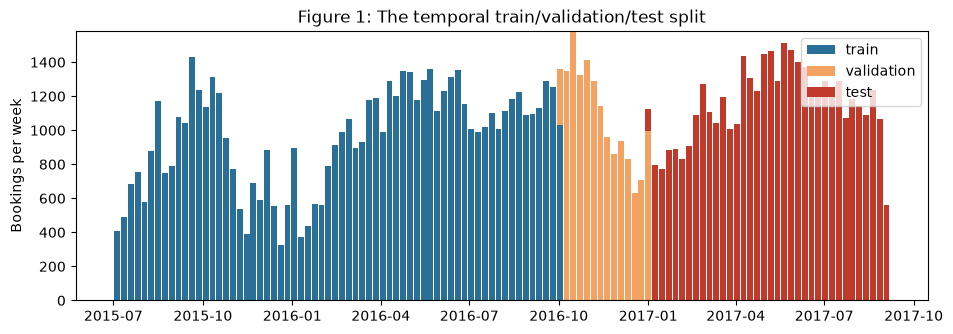

In [8]:
weekly = df.groupby([pd.Grouper(key="arrival_date", freq="W"), "split"]).size().unstack(fill_value=0)
colours = {"train": "#2a6f97", "validation": "#f4a261", "test": "#c0392b"}

fig, ax = plt.subplots(figsize=(11, 3.5))
bottom = np.zeros(len(weekly))
for part in ["train", "validation", "test"]:
    ax.bar(weekly.index, weekly[part], width=6, bottom=bottom, color=colours[part], label=part)
    bottom += weekly[part].values
ax.set_ylabel("Bookings per week")
ax.set_title("Figure 1: The temporal train/validation/test split")
ax.legend()
plt.show()

## 6. Save the clean data

`arrival_date` and `arrival_date_year` are kept so the split can be checked, but they should **not** be used as model features: the test year (2017) never appears in training.

In [9]:
df = df.drop(columns="arrival_date_day_of_month")
df.to_csv("hotel_bookings_clean.csv", index=False)
print(f"Saved hotel_bookings_clean.csv: {df.shape[0]:,} bookings, {df.shape[1]} columns")
print(list(df.columns))

Saved hotel_bookings_clean.csv: 118,558 bookings, 30 columns
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type', 'adr', 'total_of_special_requests', 'has_agent', 'has_company', 'total_nights', 'total_guests', 'arrival_date', 'split']


**Using the file in a model notebook:**

```python
df = pd.read_csv("hotel_bookings_clean.csv")
train, val, test = (df[df.split == s] for s in ["train", "validation", "test"])
```

Categorical columns are stored as text. Python models can one-hot encode them with `pd.get_dummies`; R models can use them as factors directly.